## Andre

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
# Estilo visual
sns.set(style="whitegrid", palette="gray")

In [ ]:
# Carregar o arquivo CSV
df = pd.read_csv("../execution_info_all_dnas.csv")

In [ ]:
# Preparar DataFrame longo
df_long = pd.DataFrame({
    'file': list(df['file']) * 2,
    'run': list(df['run']) * 2,
    'algorithm': ['Huffman'] * len(df) + ['LZW'] * len(df),
    'compressing_time': pd.concat([df['huffman_compressing_time'], df['lzw_compressing_time']], ignore_index=True),
    'decompressing_time': pd.concat([df['huffman_decompressing_time'], df['lzw_decompressing_time']], ignore_index=True),
    'compressed_size': pd.concat([df['huffman_compressed_file_size'], df['lzw_compressed_file_size']], ignore_index=True)
})

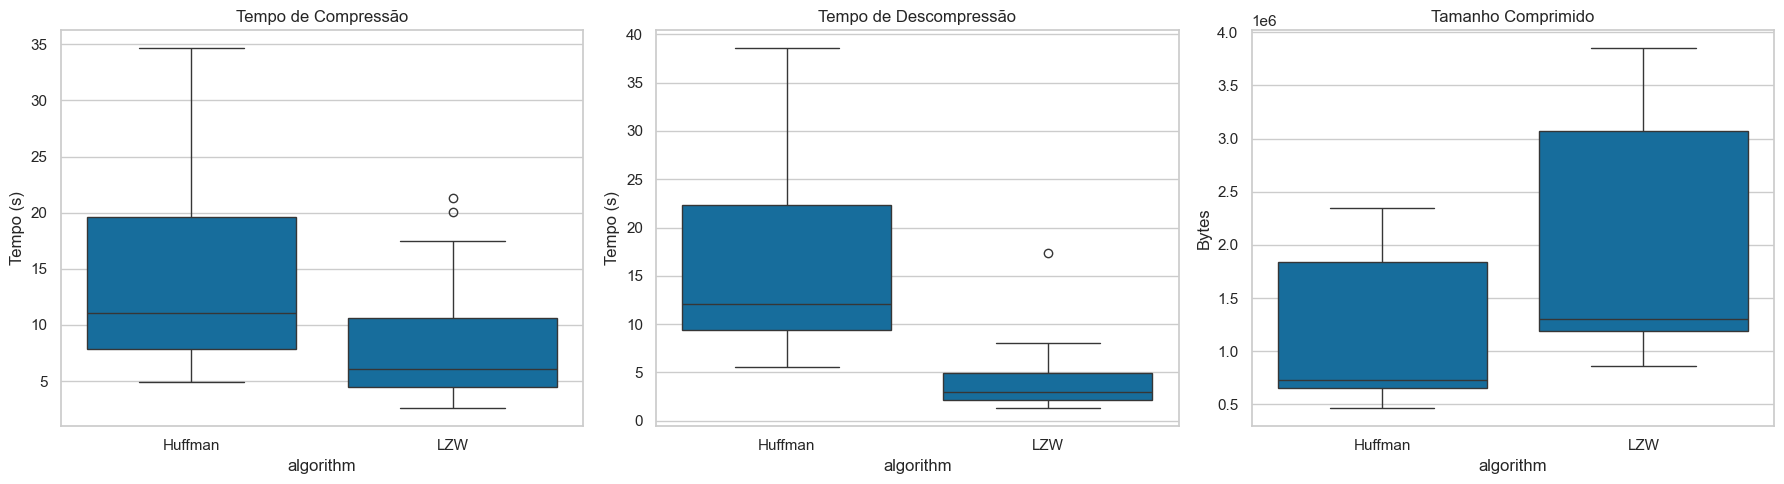

/var/folders/x0/n25cm8mn1y3gbcy7sltn4bmr0000gn/T/ipykernel_89776/2313480125.py:25: UserWarning: The palette list has more values (8) than needed (2), which may not be intended.
  sns.barplot(data=df_avg, x='file', y='compressing_time', hue='algorithm', palette=palette)


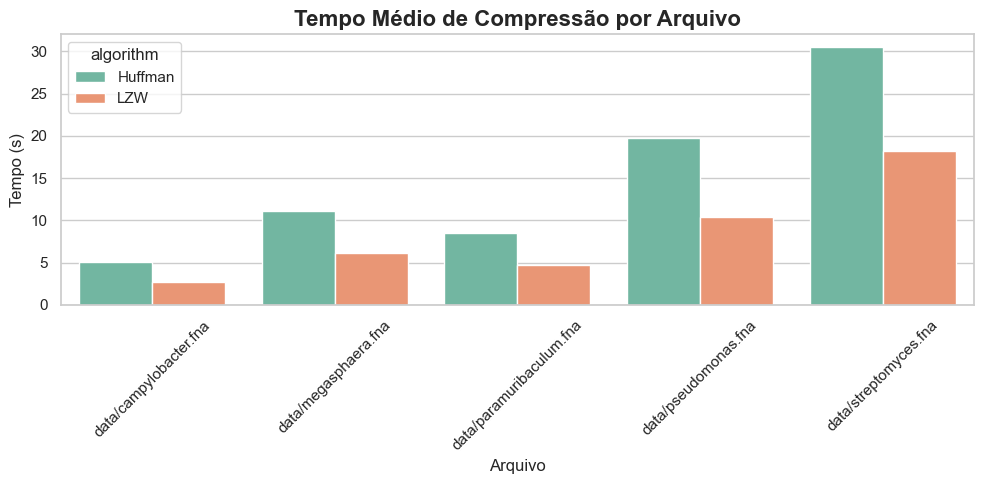

/var/folders/x0/n25cm8mn1y3gbcy7sltn4bmr0000gn/T/ipykernel_89776/2313480125.py:34: UserWarning: The palette list has more values (8) than needed (2), which may not be intended.
  sns.barplot(data=df_avg, x='file', y='decompressing_time', hue='algorithm', palette=palette)


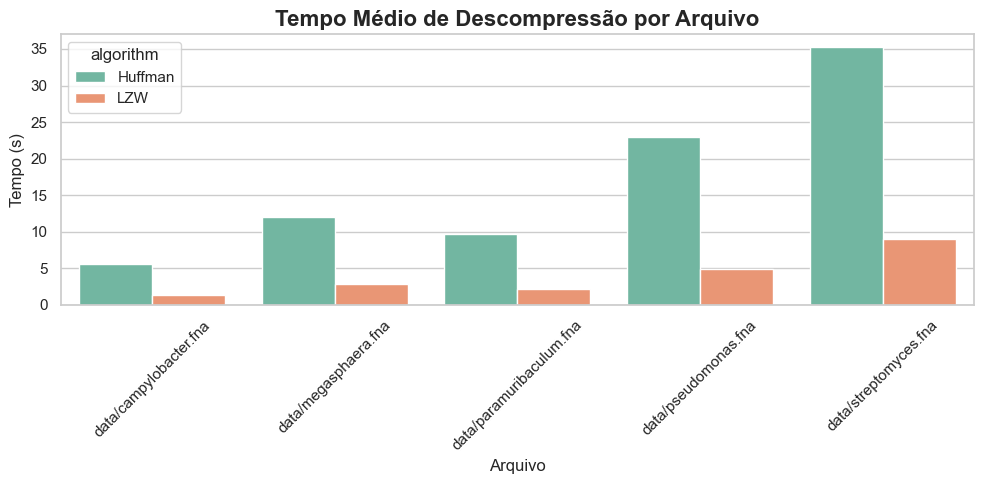

/var/folders/x0/n25cm8mn1y3gbcy7sltn4bmr0000gn/T/ipykernel_89776/2313480125.py:43: UserWarning: The palette list has more values (8) than needed (2), which may not be intended.
  sns.barplot(data=df_avg, x='file', y='compressed_size', hue='algorithm', palette=palette)


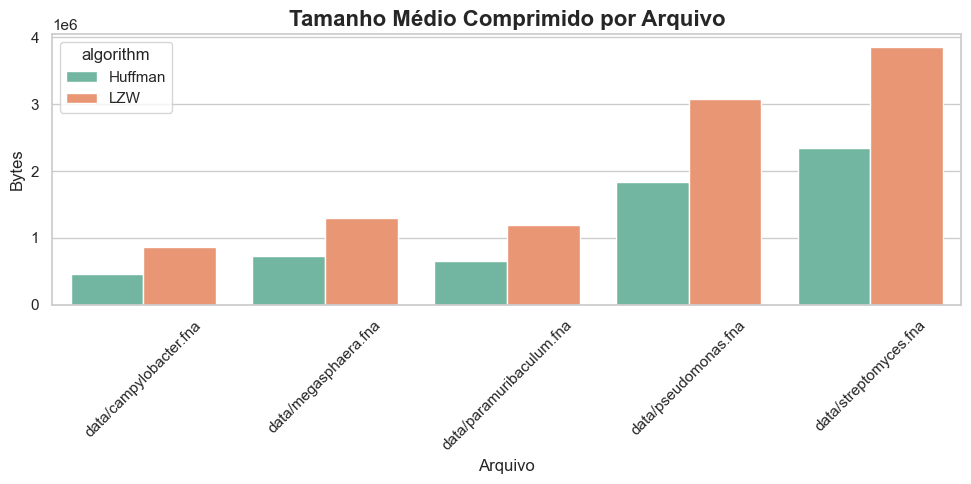

/var/folders/x0/n25cm8mn1y3gbcy7sltn4bmr0000gn/T/ipykernel_89776/2313480125.py:67: UserWarning: The palette list has more values (8) than needed (3), which may not be intended.
  sns.barplot(data=df_final_sizes, x='file', y='Tamanho (bytes)', hue='Tipo', palette=palette)


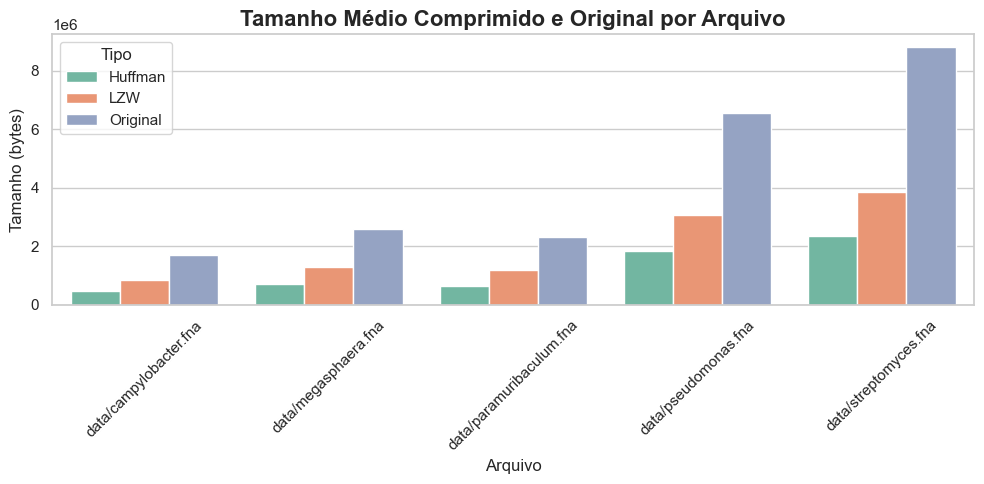

In [ ]:
# Boxplots
fig, axs = plt.subplots(1, 3, figsize=(18, 5))

sns.boxplot(data=df_long, x='algorithm', y='compressing_time', ax=axs[0])
axs[0].set_title('Tempo de Compressão')
axs[0].set_ylabel('Tempo (s)')

sns.boxplot(data=df_long, x='algorithm', y='decompressing_time', ax=axs[1])
axs[1].set_title('Tempo de Descompressão')
axs[1].set_ylabel('Tempo (s)')

sns.boxplot(data=df_long, x='algorithm', y='compressed_size', ax=axs[2])
axs[2].set_title('Tamanho Comprimido')
axs[2].set_ylabel('Bytes')

plt.tight_layout()
plt.show()

# Médias por arquivo
df_avg = df_long.groupby(['file', 'algorithm'], as_index=False)[['compressing_time', 'decompressing_time', 'compressed_size']].mean()
palette = sns.color_palette("Set2")

# Gráficos de barras
plt.figure(figsize=(10, 5))
sns.barplot(data=df_avg, x='file', y='compressing_time', hue='algorithm', palette='gray')
plt.title('Tempo Medio de Compressão por Arquivo', fontsize=16, fontweight='bold')
plt.ylabel('Tempo (s)')
plt.xlabel('Arquivo')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 5))
sns.barplot(data=df_avg, x='file', y='decompressing_time', hue='algorithm', palette=palette)
plt.title('Tempo Médio de Descompressão por Arquivo', fontsize=16, fontweight='bold')
plt.ylabel('Tempo (s)')
plt.xlabel('Arquivo')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 5))
sns.barplot(data=df_avg, x='file', y='compressed_size', hue='algorithm', palette=palette)
plt.title('Tamanho Médio Comprimido por Arquivo', fontsize=16, fontweight='bold')
plt.ylabel('Bytes')
plt.xlabel('Arquivo')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Comparação com o tamanho original
original_sizes = df.groupby('file', as_index=False)['file_size'].mean()
df_avg_with_size = pd.merge(df_avg, original_sizes, on='file')

huffman = df_avg_with_size[df_avg_with_size['algorithm'] == 'Huffman'][['file', 'compressed_size']].rename(columns={'compressed_size': 'Tamanho (bytes)'})
huffman['Tipo'] = 'Huffman'

lzw = df_avg_with_size[df_avg_with_size['algorithm'] == 'LZW'][['file', 'compressed_size']].rename(columns={'compressed_size': 'Tamanho (bytes)'})
lzw['Tipo'] = 'LZW'

original = original_sizes.rename(columns={'file_size': 'Tamanho (bytes)'})
original['Tipo'] = 'Original'

df_final_sizes = pd.concat([huffman, lzw, original], ignore_index=True)

plt.figure(figsize=(10, 5))
sns.barplot(data=df_final_sizes, x='file', y='Tamanho (bytes)', hue='Tipo', palette=palette)
plt.title('Tamanho Médio Comprimido e Original por Arquivo', fontsize=16, fontweight='bold')
plt.ylabel('Tamanho (bytes)')
plt.xlabel('Arquivo')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### testing with one file

In [11]:
file_path = Path(dir_with_files, "campylobacter.fna")
dna_sequence = []
counting_bases = {
    "A": 0,
    "C": 0,
    "G": 0,
    "T": 0,
}
bases = set(counting_bases.keys())
with open(file_path, "r") as f:
    content = f.readlines()
    for line in content:
        line = line.strip()
        if not line.startswith(">"):
            for base in counting_bases.keys():
                counting_bases[base] += line.count(base)
            if set(line) - bases:
                print(line)

In [12]:
counting_bases

{'A': 585214, 'C': 260245, 'G': 267675, 'T': 568836}

## Chat GPT

In [1]:
import matplotlib.pyplot as plt

In [2]:
input_sizes = [1000, 5000, 10000, 20000]  # em número de caracteres
practical_huffman = [8.0, 10.2, 13.1, 16.5]  # dados reais coletados
practical_lzw = [7.5, 9.0, 11.0, 13.5]      # idem

In [3]:
# estimativas teóricas com base no crescimento esperado
expected_huffman = [n * 0.0015 + 1 for n in input_sizes]
expected_lzw = [n * 0.001 + 1 for n in input_sizes]

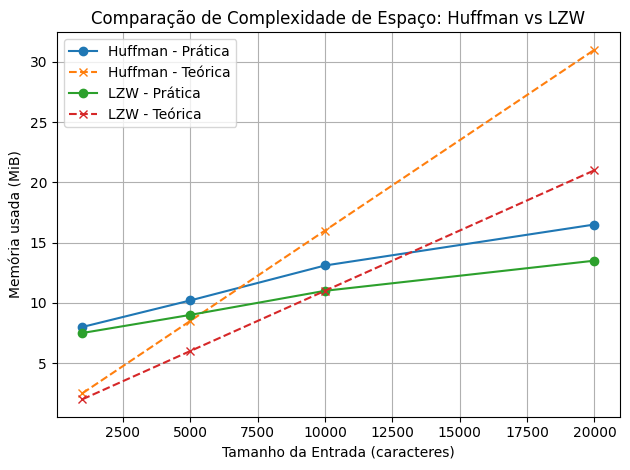

In [4]:
plt.plot(input_sizes, practical_huffman, label='Huffman - Prática', marker='o')
plt.plot(input_sizes, expected_huffman, label='Huffman - Teórica', linestyle='--', marker='x')

plt.plot(input_sizes, practical_lzw, label='LZW - Prática', marker='o')
plt.plot(input_sizes, expected_lzw, label='LZW - Teórica', linestyle='--', marker='x')

plt.xlabel('Tamanho da Entrada (caracteres)')
plt.ylabel('Memória usada (MiB)')
plt.title('Comparação de Complexidade de Espaço: Huffman vs LZW')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

## using our data

In [8]:
import json

In [2]:
import pandas as pd

In [3]:
import os

In [4]:
os.chdir("..")

In [5]:
execution_info_files = [file for file in os.listdir(".") if file.startswith("execution_info") and file.endswith(".json")]

In [6]:
execution_info_files

['execution_info_streptomyces_20250728_215827.json',
 'execution_info_paramuribaculum_20250728_222115.json',
 'execution_info_pseudomonas_20250728_215733.json',
 'execution_info_trypanosoma_cruzi_20250728_215945.json',
 'execution_info_pseudomonas_20250728_222201.json',
 'execution_info_paramuribaculum_20250728_215648.json',
 'execution_info_campylobacter_20250728_222058.json',
 'execution_info_megasphaera_20250728_222137.json',
 'execution_info_campylobacter_20250728_215634.json',
 'execution_info_megasphaera_20250728_215711.json']

In [9]:
all_execution_info = list()

for file in execution_info_files:
    with open(file, "r") as f:
        execution_info = json.load(f)
        all_execution_info.append(execution_info)

In [10]:
df_execution_info = pd.DataFrame(all_execution_info)

In [13]:
df_execution_info

,file,run,file_size,huffman_compressing_time,huffman_compressing_meemory_current,huffman_compressing_memory_peak,huffman_decompressing_time,huffman_decompressing_meemory_current,huffman_decompressing_memory_peak,huffman_compressed_file_size,...,lzw_decompressing_time,lzw_decompressing_meemory_current,lzw_decompressing_memory_peak,lzw_compressed_file_size,A,C,G,T,N,has_extra_chars
0,data/streptomyces.fna,1,8798053,23.852801,4226,48851659,29.062920,5375,39851398,2343443,...,7.573135,4740,174556260,3848831,NaN,NaN,NaN,NaN,NaN,NaN
1,data/paramuribaculum.fna,1,2314132,7.348788,4643,13473084,8.681113,7194,11119090,653133,...,1.966701,5734,50673839,1191416,523389.0,637434.0,611859.0,507924.0,9.0,False
2,data/pseudomonas.fna,1,6552708,19.182314,4491,37983360,20.042928,6374,31257325,1837790,...,4.593165,4818,154643185,3072488,NaN,NaN,NaN,NaN,NaN,NaN
3,data/trypanosoma_cruzi.fna,1,94118119,400.102056,4287,761374440,570.023521,5380,663193496,39010569,...,74.230137,4808,1557209171,35006528,NaN,NaN,NaN,NaN,NaN,NaN
4,data/pseudomonas.fna,1,6552708,20.584172,4491,37983360,25.455357,6248,31257199,1837790,...,5.179230,4818,154643185,3072488,1335532.0,1887551.0,1893568.0,1340536.0,193.0,False
5,data/paramuribaculum.fna,1,2314132,7.517097,4643,13473084,8.736043,7194,11119090,653133,...,2.291360,5671,50673776,1191416,NaN,NaN,NaN,NaN,NaN,NaN
6,data/campylobacter.fna,1,1708184,5.848964,7039,9654813,6.711802,8710,7925711,465201,...,1.382574,7307,39428008,858659,585214.0,260245.0,267675.0,568836.0,0.0,False
7,data/megasphaera.fna,1,2576026,8.230787,4587,15040075,8.961293,6438,12412297,729241,...,2.115107,5458,54712827,1303660,601829.0,680114.0,677444.0,578938.0,0.0,False
8,data/campylobacter.fna,1,1708184,4.606261,7039,9654813,5.505370,8710,7925711,465201,...,1.272783,7307,39428008,858659,NaN,NaN,NaN,NaN,NaN,NaN
9,data/megasphaera.fna,1,2576026,7.186331,4587,15040075,9.000710,6375,12412297,729241,...,2.035630,5458,54712827,1303660,NaN,NaN,NaN,NaN,NaN,NaN


In [14]:
df_execution_info.to_csv("execution_info_from_notebook.csv", index=False)